# DATA

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score

CACHE = "cache"            # imágenes redimensionadas y particiones
os.makedirs(CACHE, exist_ok=True)

In [2]:
ds = load_dataset("jaeha-choi/TickTockVQA")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['ampm', 'attribution_required', 'clock_type', 'commercial_use', 'design', 'environment', 'hour', 'image_hash', 'image_name', 'image_path', 'license', 'license_notes', 'license_type', 'license_url', 'minute', 'redistribution_allowed', 'source', 'source_url', 'time_string', 'transformation', 'split', 'image'],
        num_rows: 7236
    })
    test: Dataset({
        features: ['ampm', 'attribution_required', 'clock_type', 'commercial_use', 'design', 'environment', 'hour', 'image_hash', 'image_name', 'image_path', 'license', 'license_notes', 'license_type', 'license_url', 'minute', 'redistribution_allowed', 'source', 'source_url', 'time_string', 'transformation', 'split', 'image'],
        num_rows: 5247
    })
})


In [ ]:
N = 20
nrows, ncols = 4, 5
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 12), constrained_layout=True)
for ax, i in zip(axs.flat, range(N)):
    sample = ds["train"][i]
    ax.set_axis_off()
    ax.imshow(sample["image"])
    ax.set_title(f"{sample['hour']}:{sample['minute']:02d} {sample['ampm'] or ''}", fontsize=9)
plt.show()

In [4]:
# hour_acc: hora exacta | min_acc: minuto con +-2 | full_acc: ambas | mae: error medio en minutos (ciclo de 12 h)
# una predicción inválida (-1) cuenta como fallo
def evaluate_clock(yh, ym, ph, pm, tol=2):
    yh, ym, ph, pm = (np.asarray(v).astype(int) for v in (yh, ym, ph, pm))
    valid = ph >= 0
    hour_ok = valid & (ph == yh)
    dm = np.abs(pm - ym) % 60; dm = np.minimum(dm, 60 - dm)
    min_ok = valid & (dm <= tol)
    dt = np.abs(np.where(valid, ph * 60 + pm, 0) - (yh * 60 + ym)) % 720; dt = np.minimum(dt, 720 - dt)
    return {"hour_acc": 100 * hour_ok.mean(), "min_acc": 100 * min_ok.mean(),
            "full_acc": 100 * (hour_ok & min_ok).mean(), "exact_acc": 100 * (hour_ok & (pm == ym)).mean(),
            "mae": dt.mean()}

def guardar_pred(nombre, split, m, ph, pm, logp=None):
    df = pd.DataFrame({"idx": m.idx.values, "hour": m.hour.values, "minute": m.minute.values,
                       "pred_hour": np.asarray(ph), "pred_minute": np.asarray(pm)})
    r = evaluate_clock(df.hour, df.minute, df.pred_hour, df.pred_minute)
    print(f"{nombre:28s} {split:5s} | hora {r['hour_acc']:6.2f} | min±2 {r['min_acc']:6.2f} | "
          f"completa {r['full_acc']:6.2f} | MAE {r['mae']:6.1f}")
    return r

# resultados publicados (test), para comparar
paper = pd.DataFrame({
    "Qwen2.5-VL-7B zero-shot":  [17.65, 22.44, 6.04, 148.62],
    "It's About Time":          [28.95, 25.00, 18.54, 135.15],
    "Qwen2.5-VL-7B + SFT":      [33.18, 41.51, 20.34, 104.31],
    "Qwen2.5-VL-7B + Swap-DPO": [35.39, 46.16, 23.06, 96.42],
    "Gemma3-12B + Swap-DPO":    [46.67, 57.54, 35.32, 81.86],
    "Llama-3.2-11B + Swap-DPO": [56.41, 66.69, 46.22, 61.93]}, index=["hour_acc", "min_acc", "full_acc", "mae"]).T
paper

,hour_acc,min_acc,full_acc,mae
Qwen2.5-VL-7B zero-shot,17.65,22.44,6.04,148.62
It's About Time,28.95,25.00,18.54,135.15
Qwen2.5-VL-7B + SFT,33.18,41.51,20.34,104.31
Qwen2.5-VL-7B + Swap-DPO,35.39,46.16,23.06,96.42
Gemma3-12B + Swap-DPO,46.67,57.54,35.32,81.86
Llama-3.2-11B + Swap-DPO,56.41,66.69,46.22,61.93


## Exploración

   hour  minute         clock_type environment    design transformation
0    10      40        Post clocks     Outdoor   [Roman]         Normal
1     4      58  Alarm/Desk clocks      Indoor  [Arabic]         Normal
2     2      18        Wall clocks      Indoor  [Arabic]         Normal
3     8      35        Wall clocks      Indoor  [Arabic]         Normal
4     2       0       Tower clocks     Outdoor   [Roman]         Normal
horas fuera de 1..12: [0, 15] []


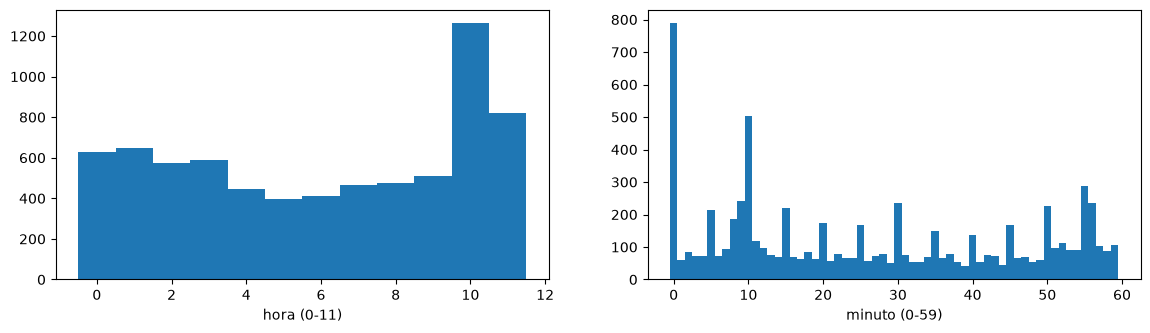

10:10    4.67
10:09    2.57
11:56    2.40
3:00     1.56
11:55    1.56
9:00     1.53
10:08    1.51
7:00     1.42
Name: count, dtype: float64
clock_type
ETC                    1629
Wall clocks            1506
Tower clocks           1214
Alarm/Desk clocks      1034
Graphic/Illustrated     834
Wristwatches            595
Post clocks             424
Name: count, dtype: int64
Hashes compartidos train/test: 1


In [5]:
train_df = ds["train"].remove_columns(["image"]).to_pandas()
test_df = ds["test"].remove_columns(["image"]).to_pandas()
print(train_df[["hour", "minute", "clock_type", "environment", "design", "transformation"]].head())
print("horas fuera de 1..12:", sorted(set(train_df.hour) - set(range(1, 13))), sorted(set(test_df.hour) - set(range(1, 13))))

fig, axs = plt.subplots(1, 2, figsize=(14, 3.5))
axs[0].hist(train_df.hour % 12, bins=np.arange(13) - 0.5); axs[0].set_xlabel("hora (0-11)")
axs[1].hist(train_df.minute, bins=np.arange(61) - 0.5); axs[1].set_xlabel("minuto (0-59)")
plt.show()

hm = (train_df.hour.astype(str) + ":" + train_df.minute.map("{:02d}".format)).value_counts()
print((100 * hm.head(8) / len(train_df)).round(2))
print(train_df.clock_type.value_counts())

shared = set(train_df.image_hash) & set(test_df.image_hash)
print(f"Hashes compartidos train/test: {len(shared)}")

In [6]:
# train y test vienen de fuentes distintas (test: COCO, Open Images, ClockMovies)
print(pd.concat([train_df.source.value_counts(), test_df.source.value_counts()], axis=1, keys=["train", "test"]).fillna(0).astype(int))
cerca_1010 = (train_df.hour % 12 == 10) & train_df.minute.between(7, 13)
fuentes = pd.DataFrame({"n": train_df.groupby("source").size(),
                        "% 10:07-10:13": 100 * cerca_1010.groupby(train_df.source).mean()})
tipos = pd.crosstab(train_df.source, train_df.clock_type, normalize="index") * 100
pd.concat([fuentes, tipos], axis=1).round(1)

              train  test
source                   
CC12M          3677     0
SBU            1533     0
VisualGenome   1246     0
ImageNet        780     0
coco2017          0  2063
OpenImages        0  1940
ClockMovies       0  1244


,n,% 10:07-10:13,Alarm/Desk clocks,ETC,Graphic/Illustrated,Post clocks,Tower clocks,Wall clocks,Wristwatches
source,,,,,,,,,
CC12M,3677,18.8,22.9,21.6,20.9,1.8,2.6,14.3,15.7
ImageNet,780,5.8,14.0,28.8,4.1,6.3,3.2,42.1,1.5
SBU,1533,0.9,3.0,21.3,1.4,8.2,46.5,19.7,0.0
VisualGenome,1246,1.3,2.9,22.6,0.9,14.6,30.4,28.2,0.4


In [7]:
print("tipos de reloj en test (%):")
(100 * pd.crosstab(test_df.source, test_df.clock_type, normalize="index")).round(1)

tipos de reloj en test (%):


clock_type,Alarm/Desk clocks,ETC,Graphic/Illustrated,Post clocks,Tower clocks,Wall clocks,Wristwatches
source,,,,,,,
ClockMovies,17.5,8.5,0.1,2.2,3.6,53.3,14.8
OpenImages,7.6,4.6,2.4,7.3,10.8,44.1,23.1
coco2017,4.9,3.3,0.5,19.7,21.6,49.5,0.5


## Particiones

In [8]:
#validación: todas las imágenes de Visual Genome 
#asi train/val están separados por fuente igual que train/test
def letterbox(img, size):
    s = max(img.size); canvas = Image.new("RGB", (s, s))
    canvas.paste(img, ((s - img.width) // 2, (s - img.height) // 2))
    return canvas.resize((size, size), Image.Resampling.BICUBIC)

def lista(d):
    return "|".join(d) if isinstance(d, (list, tuple, np.ndarray)) else d

meta = pd.concat([df.assign(split=s, idx=np.arange(len(df))) for s, df in [("train", train_df), ("test", test_df)]], ignore_index=True)
meta["hour"] = meta.hour.astype(int) % 12
meta["minute"] = meta.minute.astype(int)
meta["design"] = meta.design.map(lista)
meta["image_hash"] = meta.image_hash.fillna(meta.split + "_" + meta.idx.astype(str))

fuente = meta.source.astype(str).str.lower().str.replace(r"[^a-z]", "", regex=True)
meta["subset"] = meta.split
meta.loc[(meta.split == "train") & fuente.str.contains("genome|^vg"), "subset"] = "val"
h_val, h_test = set(meta.image_hash[meta.subset == "val"]), set(meta.image_hash[meta.subset == "test"])
meta.loc[(meta.subset == "train") & meta.image_hash.isin(h_val | h_test), "subset"] = "excluida"
meta.loc[(meta.subset == "val") & meta.image_hash.isin(h_test), "subset"] = "excluida"
assert (meta.subset == "val").sum() > 500

cols = ["split", "idx", "subset", "source", "hour", "minute", "clock_type", "environment", "design", "image_hash"]
meta[cols].to_csv(f"{CACHE}/meta.csv", index=False)
print(pd.crosstab(meta.source, meta.subset))

subset        excluida  test  train   val
source                                   
CC12M                0     0   3677     0
ClockMovies          0  1244      0     0
ImageNet             4     0    776     0
OpenImages           0  1940      0     0
SBU                  0     0   1533     0
VisualGenome         0     0      0  1246
coco2017             0  2063      0     0


In [9]:
# orig: lado mayor 1024 (para YOLO) | full: imagen completa cuadrada 512x512
os.makedirs(f"{CACHE}/orig", exist_ok=True); os.makedirs(f"{CACHE}/full", exist_ok=True)
t0 = time.time()
for split in ["train", "test"]:
    for i in range(len(ds[split])):
        if os.path.exists(f"{CACHE}/orig/{split}_{i}.jpg") and os.path.exists(f"{CACHE}/full/{split}_{i}.jpg"):
            continue
        img = ds[split][i]["image"].convert("RGB")
        big = img.copy(); big.thumbnail((1024, 1024))
        big.save(f"{CACHE}/orig/{split}_{i}.jpg", quality=95)
        letterbox(img, 512).save(f"{CACHE}/full/{split}_{i}.jpg", quality=95)
print(f"caché lista ({time.time() - t0:.0f}s)")

meta = pd.read_csv(f"{CACHE}/meta.csv")
M = {s: meta[meta.subset == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print(meta.subset.value_counts())

caché lista (0s)
subset
train       5986
test        5247
val         1246
excluida       4
Name: count, dtype: int64


In [10]:
# matrices N x 4096 (gris 64x64) para PCA y modelos lineales
SIZE = 64
def load_xy(s):
    X = np.stack([np.asarray(Image.open(f"{CACHE}/full/{r.split}_{r.idx}.jpg").convert("L").resize((SIZE, SIZE), Image.Resampling.BILINEAR))
                  for r in M[s].itertuples()]).astype(np.float32).reshape(len(M[s]), -1) / 255.
    return X, M[s].hour.values, M[s].minute.values

X_train, yh_train, ym_train = load_xy("train")
X_val, yh_val, ym_val = load_xy("val")
X_test, yh_test, ym_test = load_xy("test")
print(X_train.shape, X_val.shape, X_test.shape)

(5986, 4096) (1246, 4096) (5247, 4096)


## Baselines

In [11]:
rng = np.random.default_rng(0)
for s in ["val", "test"]:
    guardar_pred("azar", s, M[s], rng.integers(0, 12, len(M[s])), rng.integers(0, 60, len(M[s])))
t_moda = np.bincount(yh_train * 60 + ym_train, minlength=720).argmax()
print("moda:", t_moda // 60, ":", t_moda % 60)
for s in ["val", "test"]:
    guardar_pred("moda", s, M[s], np.full(len(M[s]), t_moda // 60), np.full(len(M[s]), t_moda % 60))

azar                         val   | hora   8.67 | min±2   8.11 | completa   0.80 | MAE  181.2
azar                         test  | hora   8.18 | min±2   8.27 | completa   0.69 | MAE  179.0
moda: 10 : 10
moda                         val   | hora  10.03 | min±2   8.03 | completa   1.12 | MAE  180.0
moda                         test  | hora   9.41 | min±2   8.50 | completa   1.41 | MAE  177.3


## PCA

{0.8: 13, 0.9: 56, 0.95: 176, 0.99: 816}


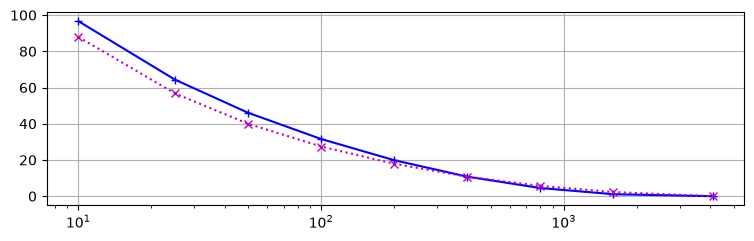

In [12]:
max_K = np.min(X_train.shape); pca = PCA(n_components=max_K, random_state=23).fit(X_train)
Z_train = pca.transform(X_train); Z_val = pca.transform(X_val); Z_test = pca.transform(X_test)
Ks = np.array([k for k in [10, 25, 50, 100, 200, 400, 800, 1600] if k < max_K] + [max_K])
L_train = np.empty_like(Ks, dtype=float); L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy(); Z_train_K[:, K:] = 0.0; hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
    Z_test_K = Z_test.copy(); Z_test_K[:, K:] = 0.0; hX_test = pca.inverse_transform(Z_test_K)
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m'); plt.xscale("log")
cum = np.cumsum(pca.explained_variance_ratio_)
print({p: int(np.searchsorted(cum, p) + 1) for p in [0.8, 0.9, 0.95, 0.99]})

K = int(np.searchsorted(cum, 0.95) + 1); ncols = 10
fig, axs = plt.subplots(nrows=1, ncols=ncols, figsize=(18, 1.8), constrained_layout=True)
for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"Eigenclock {i}")
    ax.imshow(pca.components_[i, :].reshape((SIZE, SIZE)), cmap=plt.cm.gray, interpolation="none")
Z = Z_test[:ncols].copy(); Z[:, K:] = 0.0; hX = pca.inverse_transform(Z)
fig, axs = plt.subplots(nrows=2, ncols=ncols, figsize=(18, 3.6), constrained_layout=True)
for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{yh_test[i]}:{ym_test[i]:02d} orig.")
    ax.imshow(X_test[i].reshape((SIZE, SIZE)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"rec. K={K}")
    ax.imshow(hX[i].reshape((SIZE, SIZE)), cmap=plt.cm.gray, interpolation="none")

- Incluso conservando el 95% de la varianza, los resultados de reconstrucción son bastante malos, aunque está claro que los eigenvectors son para imágenes de solo relojes

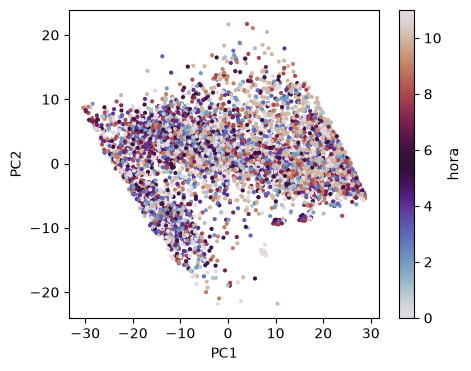

In [13]:
plt.figure(figsize=(5, 4)); plt.scatter(Z_train[:, 0], Z_train[:, 1], c=yh_train, cmap="twilight", s=4)
plt.colorbar(label="hora"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

- PCA no detecta nada a nivel de hora, las 2 componentes más importantes son incapaces de separar por horas

## Regresión logística

In [14]:
# un clasificador para la hora (12 clases) y otro para el minuto (60); K se elige en validación
Ks_lr = [k for k in [10, 25, 50, 100, 200, 400, 800] if k < max_K]
res_K = []
for K in Ks_lr:
    clf_h = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], yh_train)
    clf_m = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], ym_train)
    r = evaluate_clock(yh_val, ym_val, clf_h.predict(Z_val[:, :K]), clf_m.predict(Z_val[:, :K]))
    res_K.append({"K": K, "train_hour": 100 * clf_h.score(Z_train[:, :K], yh_train), **r})
res_K = pd.DataFrame(res_K); res_K.round(2)

,K,train_hour,hour_acc,min_acc,full_acc,exact_acc,mae
0,10,22.12,10.83,10.83,1.52,0.80,171.49
1,25,21.98,10.03,9.23,0.72,0.48,168.90
2,50,22.75,9.31,9.07,0.64,0.16,168.36
3,100,24.57,9.95,8.75,1.04,0.40,167.16
4,200,28.95,10.19,9.79,0.56,0.32,170.24
5,400,35.63,10.35,9.23,0.88,0.40,164.70
6,800,46.06,9.31,8.91,0.88,0.32,171.71


10 0.001 12.04 1.52
10 0.01 11.16 1.77
10 0.1 10.83 1.52
10 1.0 10.83 1.52


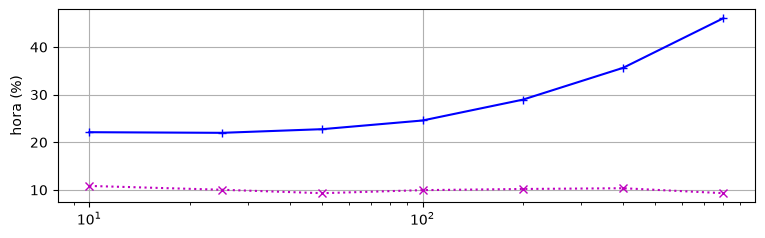

In [15]:
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(res_K.K, res_K.train_hour, '+-b', res_K.K, res_K.hour_acc, 'x:m'); plt.xscale("log"); plt.ylabel("hora (%)")
K_best = int(res_K.K[np.argmax(res_K.full_acc + res_K.hour_acc / 100)])
best = None
for C in [0.001, 0.01, 0.1, 1.0]:      # a mayor C, menor regularización
    clf_h = LogisticRegression(C=C, max_iter=500).fit(Z_train[:, :K_best], yh_train)
    clf_m = LogisticRegression(C=C, max_iter=500).fit(Z_train[:, :K_best], ym_train)
    r = evaluate_clock(yh_val, ym_val, clf_h.predict(Z_val[:, :K_best]), clf_m.predict(Z_val[:, :K_best]))
    print(K_best, C, round(r["hour_acc"], 2), round(r["full_acc"], 2))
    if best is None or r["full_acc"] + r["hour_acc"] / 100 > best[0]:
        best = (r["full_acc"] + r["hour_acc"] / 100, clf_h, clf_m)

In [16]:
# decisión conjunta: argmax de log p(h) + log p(m) sobre las 720 horas posibles
def joint(clf_h, clf_m, X):
    lph = np.full((len(X), 12), -30.0); lph[:, clf_h.classes_] = clf_h.predict_log_proba(X)
    lpm = np.full((len(X), 60), -30.0); lpm[:, clf_m.classes_] = clf_m.predict_log_proba(X)
    return (lph[:, :, None] + lpm[:, None, :]).reshape(len(X), 720)

_, clf_h, clf_m = best
for s, Z in [("val", Z_val), ("test", Z_test)]:
    lp = joint(clf_h, clf_m, Z[:, :K_best]); t = lp.argmax(1)
    guardar_pred("pca_logreg", s, M[s], t // 60, t % 60, lp)

pca_logreg                   val   | hora  11.16 | min±2  11.64 | completa   1.77 | MAE  171.5
pca_logreg                   test  | hora  10.08 | min±2  10.08 | completa   1.16 | MAE  173.9


## RL con características polinómicas

In [17]:
# con ~6000 imágenes, K pequeño: K=50 -> 1326 características, K=100 -> 5151
best = None
for K in [50, 100]:
    poly = PolynomialFeatures(2).fit(Z_train[:, :K]); sc = StandardScaler().fit(poly.transform(Z_train[:, :K]))
    F = {s: sc.transform(poly.transform(Z[:, :K])) for s, Z in [("train", Z_train), ("val", Z_val), ("test", Z_test)]}
    for C in [0.01, 0.1]:
        start = time.time()
        clf_h = LogisticRegression(C=C, max_iter=200).fit(F["train"], yh_train)
        clf_m = LogisticRegression(C=C, max_iter=200).fit(F["train"], ym_train)
        r = evaluate_clock(yh_val, ym_val, clf_h.predict(F["val"]), clf_m.predict(F["val"]))
        print(K, C, F["train"].shape, round(r["hour_acc"], 2), round(r["full_acc"], 2), f"{time.time() - start:.0f}s")
        if best is None or r["full_acc"] + r["hour_acc"] / 100 > best[0]:
            best = (r["full_acc"] + r["hour_acc"] / 100, clf_h, clf_m, F)
_, clf_h, clf_m, F = best
for s in ["val", "test"]:
    lp = joint(clf_h, clf_m, F[s]); t = lp.argmax(1)
    guardar_pred("logreg_poly", s, M[s], t // 60, t % 60, lp)

50 0.01 (5986, 1326) 9.23 1.28 22s
50 0.1 (5986, 1326) 9.63 1.2 38s
100 0.01 (5986, 5151) 10.03 0.72 41s
100 0.1 (5986, 5151) 9.79 0.88 60s
logreg_poly                  val   | hora   9.23 | min±2   7.95 | completa   1.28 | MAE  175.4
logreg_poly                  test  | hora   9.15 | min±2   9.93 | completa   1.14 | MAE  174.3


## RLineal

In [18]:
# entrada: 50 primeras componentes PCA estandarizadas (sin y con características polinómicas)
# objetivo A: (sin, cos) del ángulo de 12 h  |  objetivo B: (sin, cos) de cada aguja
sc = StandardScaler().fit(Z_train[:, :50])
P = {s: sc.transform(Z[:, :50]) for s, Z in [("train", Z_train), ("val", Z_val), ("test", Z_test)]}
poly = PolynomialFeatures(2).fit(P["train"]); P2 = {s: poly.transform(v) for s, v in P.items()}
T = {"train": yh_train * 60 + ym_train, "val": yh_val * 60 + ym_val, "test": yh_test * 60 + ym_test}

def target_12h(t):
    a = 2 * np.pi * t / 720
    return np.c_[np.sin(a), np.cos(a)]

def target_agujas(t):
    ah, am = 2 * np.pi * t / 720, 2 * np.pi * (t % 60) / 60
    return np.c_[np.sin(ah), np.cos(ah), np.sin(am), np.cos(am)]

def decode_12h(Y):
    t = np.round((np.arctan2(Y[:, 0], Y[:, 1]) % (2 * np.pi)) / (2 * np.pi) * 720).astype(int) % 720
    return t // 60, t % 60

def decode_agujas(Y):
    # minuto de la minutera; la hora se corrige con ese minuto
    m = np.round((np.arctan2(Y[:, 2], Y[:, 3]) % (2 * np.pi)) / (2 * np.pi) * 60).astype(int) % 60
    th = (np.arctan2(Y[:, 0], Y[:, 1]) % (2 * np.pi)) / (2 * np.pi) * 720
    return np.round((th - m) / 60).astype(int) % 12, m

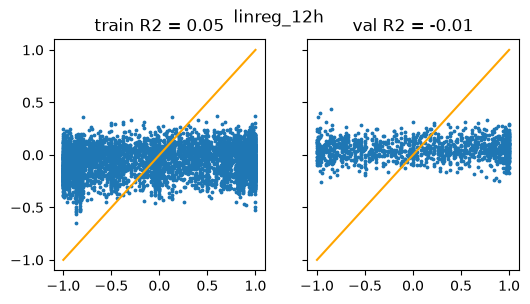

linreg_12h                   val   | hora  11.96 | min±2   7.54 | completa   0.64 | MAE  159.8
linreg_12h                   test  | hora  10.25 | min±2   8.12 | completa   0.93 | MAE  168.0


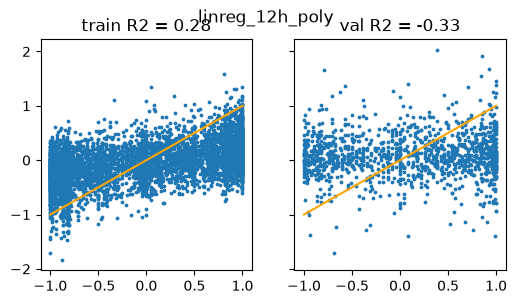

linreg_12h_poly              val   | hora   9.23 | min±2   8.11 | completa   0.96 | MAE  171.8
linreg_12h_poly              test  | hora   9.26 | min±2   8.29 | completa   0.86 | MAE  172.8


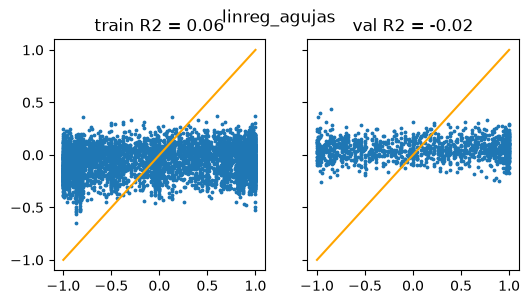

linreg_agujas                val   | hora  11.72 | min±2   8.91 | completa   1.12 | MAE  159.9
linreg_agujas                test  | hora  10.41 | min±2   8.71 | completa   0.95 | MAE  167.9


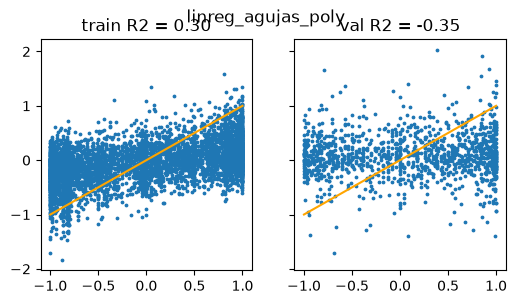

linreg_agujas_poly           val   | hora   9.47 | min±2   7.95 | completa   0.96 | MAE  171.7
linreg_agujas_poly           test  | hora   9.13 | min±2   8.61 | completa   0.82 | MAE  173.0


In [19]:
for nombre, X, target, decode in [("linreg_12h", P, target_12h, decode_12h), ("linreg_12h_poly", P2, target_12h, decode_12h),
                                  ("linreg_agujas", P, target_agujas, decode_agujas), ("linreg_agujas_poly", P2, target_agujas, decode_agujas)]:
    linreg = LinearRegression().fit(X["train"], target(T["train"]))
    y_train_pred = linreg.predict(X["train"]); y_val_pred = linreg.predict(X["val"])
    r2_train = r2_score(target(T["train"]), y_train_pred); r2_val = r2_score(target(T["val"]), y_val_pred)
    fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey='all'); fig.suptitle(nombre)
    ax = axs[0]; ax.set_title(f'train R2 = {r2_train:.2f}')
    ax.scatter(target(T["train"])[:, 0], y_train_pred[:, 0], s=3); ax.plot([-1, 1], [-1, 1], color='orange')
    ax = axs[1]; ax.set_title(f'val R2 = {r2_val:.2f}')
    ax.scatter(target(T["val"])[:, 0], y_val_pred[:, 0], s=3); ax.plot([-1, 1], [-1, 1], color='orange')
    plt.show()
    for s in ["val", "test"]:
        guardar_pred(nombre, s, M[s], *decode(linreg.predict(X[s])))